In [ ]:
!pip install sentinelhub rasterio geopandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.3/242.3 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 5.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timedelta
from sentinelhub import (
    SHConfig, BBox, CRS, SentinelHubRequest, MimeType,
    DataCollection, bbox_to_dimensions, MosaickingOrder
)
from rasterio.transform import from_bounds
from google.colab import files

# === Sentinel Hub Config ===
config = SHConfig()
config.sh_client_id = ""
config.sh_client_secret = ""
config.download_timeout_seconds = 60

# === Thar Desert bbox ===
coords = [70.905, 26.906, 70.925, 26.924]  # small bbox near Jaisalmer
region_name = "TharDesert"

# === Seasonal date ranges ===
seasons = {
    "Monsoon": ("2023-07-01", "2023-09-30"),
    "PostMonsoon": ("2023-10-01", "2023-11-30"),
    "Winter": ("2023-12-01", "2024-02-28"),
    "Summer": ("2024-03-01", "2024-05-31")
}

# === Evalscript (7 bands) ===
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["B02", "B03", "B04", "B05", "B08", "B11", "B12"],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(sample) {
  return [
    sample.B02, sample.B03, sample.B04,
    sample.B05, sample.B08, sample.B11, sample.B12
  ];
}
"""

# === Data collection ===
all_data = []
bbox = BBox(bbox=coords, crs=CRS.WGS84)
size = bbox_to_dimensions(bbox, resolution=10)

for season_name, (start, end) in seasons.items():
    print(f"\n📦 Fetching for {region_name} - {season_name}")
    try:
        request = SentinelHubRequest(
            evalscript=evalscript,
            input_data=[SentinelHubRequest.input_data(
                data_collection=DataCollection.SENTINEL2_L2A,
                time_interval=(start, end),
                mosaicking_order=MosaickingOrder.MOST_RECENT
            )],
            responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
            bbox=bbox,
            size=size,
            config=config
        )

        images = request.get_data(save_data=False)
        if not images:
            print("⚠ No image returned.")
            continue

        image = images[0]
        blue, green, red, red_edge, nir, swir1, swir2 = image[:7]

        if np.all(nir == 0) or np.all(red == 0):
            print("⚠ Image is empty (all zeros). Skipping.")
            continue

        # Compute indices
        ndvi = (nir - red) / (nir + red + 1e-6)
        savi = (nir - red) * 1.5 / (nir + red + 0.5)
        ndmi = (nir - swir1) / (nir + swir1 + 1e-6)
        evi = 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1)
        revi = (red_edge - red) / (red_edge + red + 1e-6)

        transform = from_bounds(*bbox, width=ndvi.shape[1], height=ndvi.shape[0])
        for y in range(ndvi.shape[0]):
            for x in range(ndvi.shape[1]):
                if np.isnan(ndvi[y, x]):
                    continue
                lat, lon = rasterio.transform.xy(transform, y, x)
                all_data.append({
                    "timestamp": start,
                    "region": region_name,
                    "season": season_name,
                    "latitude": lat,
                    "longitude": lon,
                    "ndvi": float(ndvi[y, x]),
                    "savi": float(savi[y, x]),
                    "ndmi": float(ndmi[y, x]),
                    "evi": float(evi[y, x]),
                    "revi": float(revi[y, x])
                })

        print(f"✅ Done for {region_name} - {season_name}")

    except Exception as e:
        print(f"❌ Error for {region_name} - {season_name}: {e}")
        continue

# === Export to CSV ===
df = pd.DataFrame(all_data)
df.to_csv("Desert_Validation_Thar.csv", index=False)
files.download("Desert_Validation_Thar.csv")


📦 Fetching for TharDesert - Monsoon
✅ Done for TharDesert - Monsoon

📦 Fetching for TharDesert - PostMonsoon
✅ Done for TharDesert - PostMonsoon

📦 Fetching for TharDesert - Winter
✅ Done for TharDesert - Winter

📦 Fetching for TharDesert - Summer
✅ Done for TharDesert - Summer


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DATA PRE-PROCESSING

import pandas as pd
from google.colab import files

# Load the previously extracted file
df = pd.read_csv("Desert_Validation_Thar.csv")

# Drop rows with missing values
df = df.dropna()

# Convert timestamp to datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Ensure all VI-related columns are numeric
vi_columns = ['latitude', 'longitude', 'ndvi', 'savi', 'ndmi', 'evi', 'revi']
df[vi_columns] = df[vi_columns].apply(pd.to_numeric, errors='coerce')

# Drop rows where NDVI is invalid (e.g., 0 or negative)
df = df[(df['ndvi'] > 0) & (df['ndvi'] <= 1)]

# Remove duplicates
df = df.drop_duplicates()

# Save cleaned file
df.to_csv("Desert_Validation_Thar_CLEANED.csv", index=False)
files.download("Desert_Validation_Thar_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
from google.colab import files

# Load the CSV file
df = pd.read_csv('Desert_Validation_Thar_CLEANED.csv')

# Select vegetation index columns for scaling
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']

# Ensure VI columns are numeric
for col in vi_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaNs in VI columns
df = df.dropna(subset=vi_columns)

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the VI columns
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip all values to range [-1, 1]
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# Save the standardized and clipped data to a new CSV
df_scaled.to_csv('Desert_Validation_Thar_STANDARDIZED.csv', index=False)
files.download("Desert_Validation_Thar_STANDARDIZED.csv")

print("✅ Z-score standardization + clipping complete. File saved.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Z-score standardization + clipping complete. File saved.


In [ ]:
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']].describe())
# to check if mean is approximately 0 == standardized data

              ndvi         savi         ndmi          evi         revi
count  2666.000000  2666.000000  2666.000000  2666.000000  2666.000000
mean     -0.131347    -0.137094    -0.051671     0.029626    -0.077394
std       0.544855     0.595761     0.527307     0.119465     0.506220
min      -0.659276    -0.766592    -1.000000    -1.000000    -1.000000
25%      -0.606673    -0.682208    -0.260239    -0.006027    -0.370928
50%      -0.314288    -0.313257    -0.042657     0.010709    -0.301683
75%       0.145433     0.233963     0.118036     0.039237     0.229336
max       1.000000     1.000000     1.000000     1.000000     1.000000


/tmp/ipython-input-12-107729317.py:51: UserWarning: Glyph 127806 (\N{EAR OF RICE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127806 (\N{EAR OF RICE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


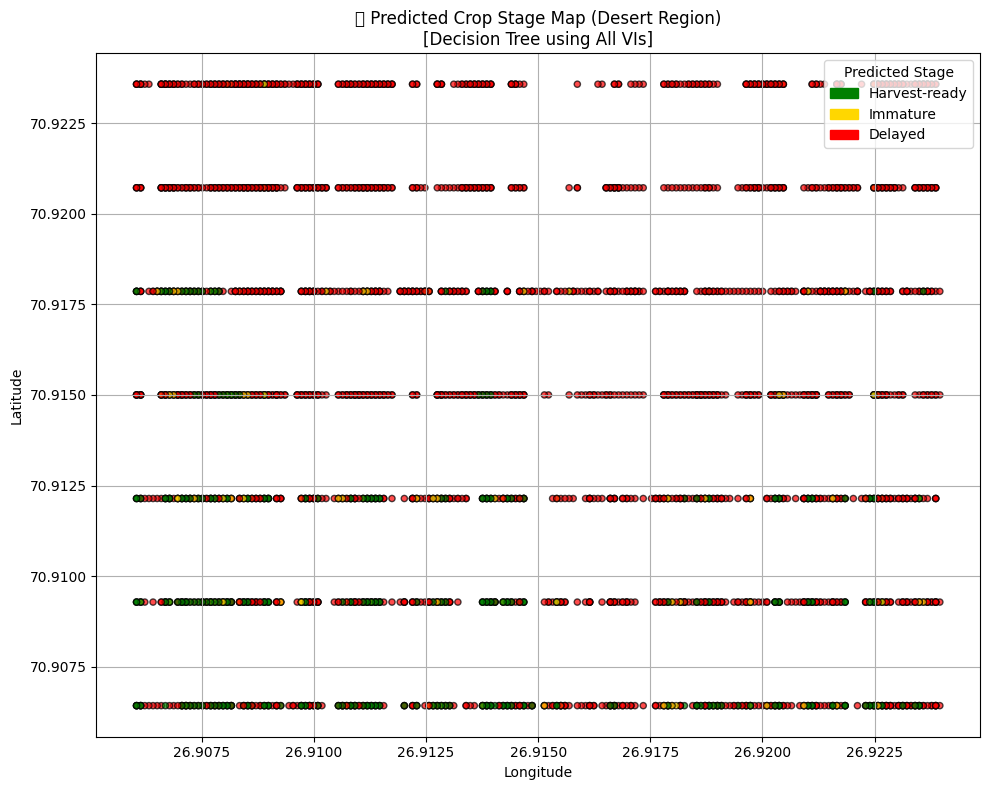

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Load your standardized desert data
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")

# Label NDVI into crop stages (same as model training)
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# Train Decision Tree on all VIs
X = df[['savi', 'ndmi', 'evi', 'revi']]
y = df['label']
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# Predict labels
df['predicted_label'] = model.predict(X)

# Assign colors to predicted classes
label_colors = {
    'Harvest-ready': 'green',
    'Immature': 'gold',
    'Delayed': 'red'
}
df['color'] = df['predicted_label'].map(label_colors)

# Plot using scatter (lat/lon instead of grid)
plt.figure(figsize=(10, 8))
plt.scatter(df['longitude'], df['latitude'],
            c=df['color'], edgecolor='k', s=20, alpha=0.7)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('🌾 Predicted Crop Stage Map (Desert Region)\n[Decision Tree using All VIs]')
plt.grid(True)

# Legend
import matplotlib.patches as mpatches
legend_patches = [mpatches.Patch(color=color, label=label) for label, color in label_colors.items()]
plt.legend(handles=legend_patches, title='Predicted Stage', loc='upper right')
plt.tight_layout()
plt.show()
df.to_csv("Desert_Classification_With_Predictions.csv", index=False)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the file with predictions
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")  # Must include 'latitude', 'longitude', 'predicted_label'

# Define color mapping for predicted classes
label_colors = {
    'Healthy': 'green',
    'Moderate': 'yellow',
    'Stressed': 'red'
}

# Map colors to each prediction
df['color'] = df['predicted_label'].map(label_colors)

# Plot using scatter for square-pixel effect
plt.figure(figsize=(8, 8))
plt.scatter(df['longitude'], df['latitude'],
            c=df['color'], s=10, marker='s', edgecolors='k', linewidth=0.1, alpha=0.9)

# Axis and title
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("🟩 Predicted Crop Health (New Region)")

# Add legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='s', color='w', label=label,
                          markerfacecolor=color, markersize=10, markeredgecolor='k')
                   for label, color in label_colors.items()]
plt.legend(handles=legend_elements, title="Predicted Class")

plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')  # Keeps it square
plt.tight_layout()
plt.show()


KeyError: 'predicted_label'

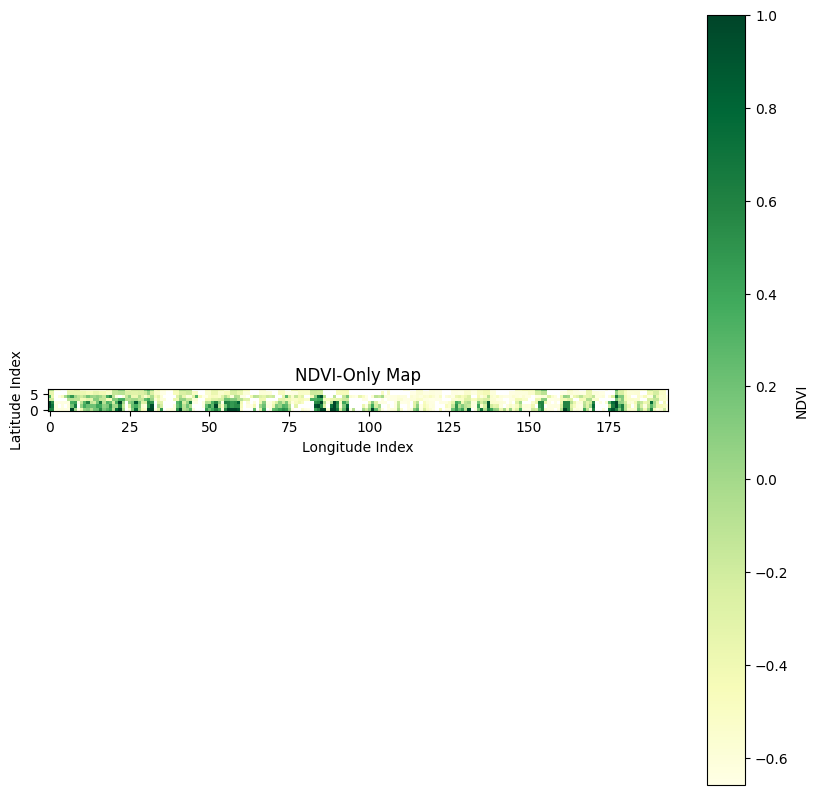

In [ ]:
# NDVI only map before ML

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your standardized NDVI data
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")

# Convert to numeric if needed (in case of formatting issues)
df['ndvi'] = pd.to_numeric(df['ndvi'], errors='coerce')

# Drop rows with missing or NaN NDVI
df = df.dropna(subset=['ndvi'])

# Optional: round lat/lon slightly to group nearby pixels
df['lat_index'] = df['latitude'].round(5)
df['lon_index'] = df['longitude'].round(5)

# Pivot the table to create a 2D NDVI grid
ndvi_map = df.pivot_table(values='ndvi', index='lat_index', columns='lon_index')

# Plot the NDVI-only map
plt.figure(figsize=(10, 10))
cmap = plt.cm.YlGn  # Green color scheme
plt.imshow(ndvi_map, cmap=cmap, origin='lower')
plt.colorbar(label='NDVI')
plt.title("NDVI-Only Map")
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.show()

In [ ]:
# Decision trees model and generate validation and test report

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 1. Load the standardized or cleaned data
df = pd.read_csv('Desert_Validation_Thar_STANDARDIZED.csv')

# 2. Create crop stage labels from NDVI (if not already present)
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# 3. Select target
X = df[['ndvi']]
y = df['label']

# 4. First split into Train (60%) and Temp (40%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# 5. Then split Temp into Validation (20%) and Test (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# 6. Create and train the Decision Tree classifier
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 7. Evaluate on Validation and Test Sets
print(" Validation Set Report:")
y_val_pred = model.predict(X_val)
print(classification_report(y_val, y_val_pred))

print("\n Test Set Report:")
y_test_pred = model.predict(X_test)
print(classification_report(y_test, y_test_pred))


 Validation Set Report:
               precision    recall  f1-score   support

      Delayed       1.00      1.00      1.00       423
Harvest-ready       1.00      1.00      1.00        81
     Immature       1.00      1.00      1.00        29

     accuracy                           1.00       533
    macro avg       1.00      1.00      1.00       533
 weighted avg       1.00      1.00      1.00       533


 Test Set Report:
               precision    recall  f1-score   support

      Delayed       1.00      1.00      1.00       424
Harvest-ready       1.00      1.00      1.00        82
     Immature       0.97      1.00      0.98        28

     accuracy                           1.00       534
    macro avg       0.99      1.00      0.99       534
 weighted avg       1.00      1.00      1.00       534



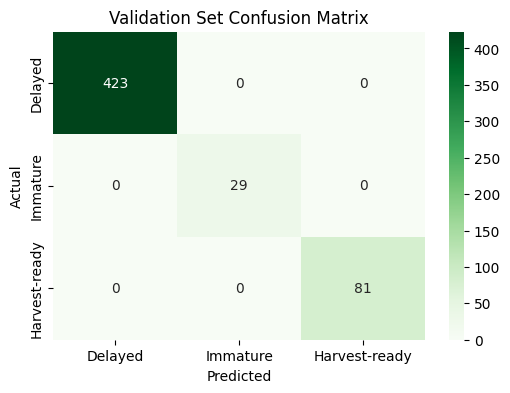

In [ ]:
# VALIDATION SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']
cm_val = confusion_matrix(y_val, y_val_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.title("Validation Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

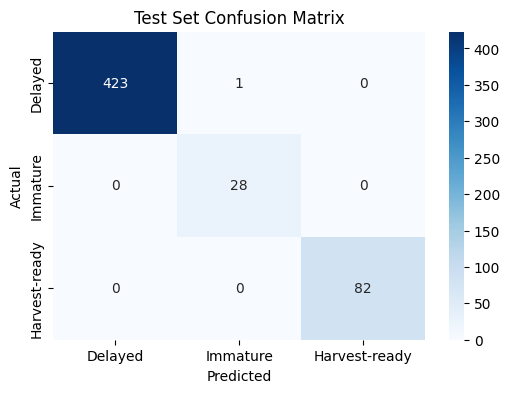

In [ ]:
# TEST SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']

cm_test = confusion_matrix(y_test, y_test_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


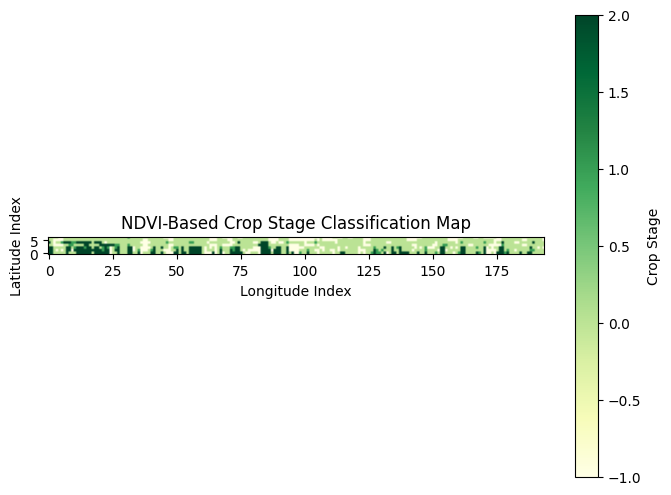

In [ ]:
# CLASSIFICATION MAP

import matplotlib.pyplot as plt
import numpy as np

# Load the cleaned data
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")

# Create the predicted labels using trained model
df['predicted_label'] = model.predict(df[['ndvi']])

# Create grid mapping (map latitudes and longitudes to indices)
latitudes = df['latitude'].values
longitudes = df['longitude'].values
lat_unique = np.sort(np.unique(latitudes))
lon_unique = np.sort(np.unique(longitudes))

lat_to_idx = {lat: i for i, lat in enumerate(lat_unique)}
lon_to_idx = {lon: i for i, lon in enumerate(lon_unique)}

# Initialize classification grid
n_rows, n_cols = len(lat_unique), len(lon_unique)
class_map = np.full((n_rows, n_cols), -1, dtype=int)  # -1 for unmapped/missing

# Label to int mapping
label_order = ['Delayed', 'Immature', 'Harvest-ready']
label_to_int = {label: idx for idx, label in enumerate(label_order)}

# Fill the grid with predictions
for lat, lon, label in zip(latitudes, longitudes, df['predicted_label']):
    row = lat_to_idx[lat]
    col = lon_to_idx[lon]
    class_map[row, col] = label_to_int[label]

# Plot the classification map
plt.figure(figsize=(8, 6))
plt.imshow(class_map, cmap='YlGn', origin='lower')
plt.colorbar(label='Crop Stage')
plt.title("NDVI-Based Crop Stage Classification Map")
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.show()

/tmp/ipython-input-23-3662832672.py:52: UserWarning: Glyph 127806 (\N{EAR OF RICE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127806 (\N{EAR OF RICE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


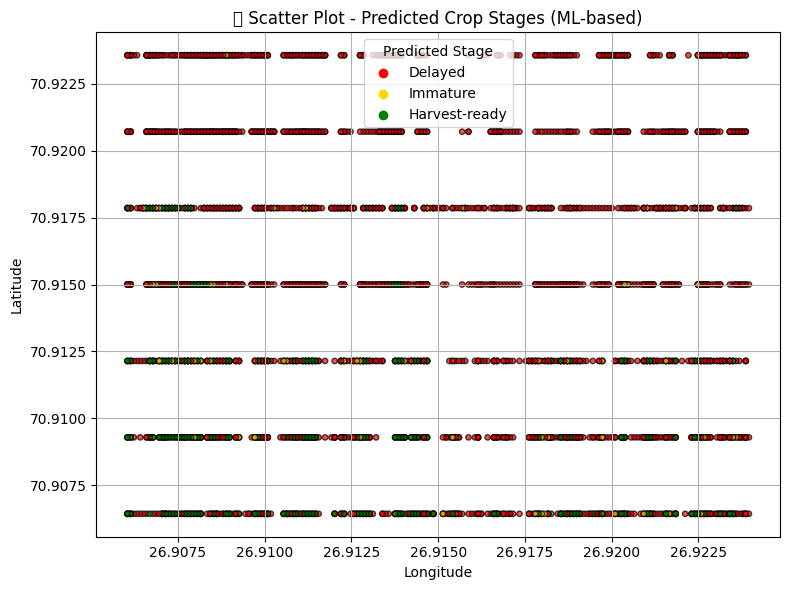

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# 1. Load the standardized dataset
df = pd.read_csv("Desert_Validation_Thar_STANDARDIZED.csv")

# 2. Prepare features and train the decision tree model (if not already done)
X = df[['ndvi']]

# Optional: define crop stage labels based on NDVI thresholds
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# Train Decision Tree Classifier
y = df['label']
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# 3. Predict crop stage
df['predicted_label'] = model.predict(X)

# 4. Define color map for crop stages
label_colors = {
    'Delayed': 'red',
    'Immature': 'gold',
    'Harvest-ready': 'green'
}
df['color'] = df['predicted_label'].map(label_colors)

# 5. Plot scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df['longitude'], df['latitude'],
            c=df['color'], edgecolor='k', s=15, alpha=0.7)

# Legend setup
for label, color in label_colors.items():
    plt.scatter([], [], color=color, label=label)
plt.legend(title="Predicted Stage")

plt.title("🌾 Scatter Plot - Predicted Crop Stages (ML-based)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.tight_layout()
plt.show()